# 🚗 Used Car Price Prediction

**Author:** Team GTA VI
**Project type:** End-to-end regression / supervised machine learning
**Tools:** Python · pandas · NumPy · scikit-learn · Matplotlib · Seaborn

---

## 1) Problem Statement

Used-car pricing in India is highly inconsistent — sellers often have no reliable
reference for what their vehicle is actually worth. The goal of this project is to
build a model that **predicts the resale price of a used car** from its core
attributes (age, kilometres driven, engine, power, fuel type, transmission, etc.).

A working model like this can power a **price-suggestion feature** that gives a new
seller an instant, data-backed estimate based on current market conditions.

## 2) Dataset

* Source: listings scraped from **CarDekho.com** (India's used-car marketplace).
* Size: **15,411 rows × 13 columns**.
* Target variable: `selling_price` (₹).

## 3) Approach

1. **Data cleaning** — check nulls, duplicates, drop redundant identifier columns.
2. **Feature engineering** — label-encode high-cardinality `model`, one-hot encode
   low-cardinality categoricals, standard-scale numerics via a `ColumnTransformer`.
3. **Model comparison** — benchmark 6 regressors (Linear, Lasso, Ridge, KNN,
   Decision Tree, Random Forest).
4. **Hyperparameter tuning** — `RandomizedSearchCV` on the two best models.
5. **Final evaluation** — pick the model with the best generalisation (test R²).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

%matplotlib inline

In [4]:
df = pd.read_csv(r"./cardekho_imputated.csv", index_col=[0])

In [5]:
df.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


## Data Cleaning
### Handling Missing values

* Handling Missing values
* Handling Duplicates
* Check data type
* Understand the dataset

In [32]:
## Check Null Values
##Check features with nan value
df.isnull().sum()
# Missing Value Analysis
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df)
    ) * 100
})

display(missing_values)

,Missing Count,Missing Percentage
model,0,0.0
vehicle_age,0,0.0
km_driven,0,0.0
seller_type,0,0.0
fuel_type,0,0.0
transmission_type,0,0.0
mileage,0,0.0
engine,0,0.0
max_power,0,0.0
seats,0,0.0


In [7]:
## Remove Unnecessary Columns
df.drop('car_name', axis=1, inplace=True)
df.drop('brand', axis=1, inplace=True)

In [8]:
df.head()

,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [9]:
df['model'].unique()

array(['Alto', 'Grand', 'i20', 'Ecosport', 'Wagon R', 'i10', 'Venue',
       'Swift', 'Verna', 'Duster', 'Cooper', 'Ciaz', 'C-Class', 'Innova',
       'Baleno', 'Swift Dzire', 'Vento', 'Creta', 'City', 'Bolero',
       'Fortuner', 'KWID', 'Amaze', 'Santro', 'XUV500', 'KUV100', 'Ignis',
       'RediGO', 'Scorpio', 'Marazzo', 'Aspire', 'Figo', 'Vitara',
       'Tiago', 'Polo', 'Seltos', 'Celerio', 'GO', '5', 'CR-V',
       'Endeavour', 'KUV', 'Jazz', '3', 'A4', 'Tigor', 'Ertiga', 'Safari',
       'Thar', 'Hexa', 'Rover', 'Eeco', 'A6', 'E-Class', 'Q7', 'Z4', '6',
       'XF', 'X5', 'Hector', 'Civic', 'D-Max', 'Cayenne', 'X1', 'Rapid',
       'Freestyle', 'Superb', 'Nexon', 'XUV300', 'Dzire VXI', 'S90',
       'WR-V', 'XL6', 'Triber', 'ES', 'Wrangler', 'Camry', 'Elantra',
       'Yaris', 'GL-Class', '7', 'S-Presso', 'Dzire LXI', 'Aura', 'XC',
       'Ghibli', 'Continental', 'CR', 'Kicks', 'S-Class', 'Tucson',
       'Harrier', 'X3', 'Octavia', 'Compass', 'CLS', 'redi-GO', 'Glanza',
       

In [10]:
## Getting All Different Types OF Features
num_features = [feature for feature in df.columns if df[feature].dtype != 'O']
print('Num of Numerical Features :', len(num_features))
cat_features = [feature for feature in df.columns if df[feature].dtype == 'O']
print('Num of Categorical Features :', len(cat_features))
discrete_features=[feature for feature in num_features if len(df[feature].unique())<=25]
print('Num of Discrete Features :',len(discrete_features))
continuous_features=[feature for feature in num_features if feature not in discrete_features]
print('Num of Continuous Features :',len(continuous_features))

Num of Numerical Features : 7
Num of Categorical Features : 4
Num of Discrete Features : 2
Num of Continuous Features : 5


In [30]:
# Dataset Overview
print("Dataset Shape:", df.shape)
print("\nTotal Records:", df.shape[0])
print("Total Features:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

# Numerical Summary
print("\nNumerical Features Summary:")
display(df.describe().T)

# Categorical Summary
print("\nCategorical Features Summary:")
display(df.describe(include="object").T)

# Unique Values
print("\nUnique Values in Each Column:")
display(df.nunique())

# Duplicate Records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (15411, 11)

Total Records: 15411
Total Features: 11

Column Names:
['model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Numerical Features Summary:


,count,mean,std,min,25%,50%,75%,max
vehicle_age,15411.0,6.036338,3.013291,0.0,4.0,6.00,8.0,29.00
km_driven,15411.0,55616.480631,51618.548422,100.0,30000.0,50000.00,70000.0,3800000.00
mileage,15411.0,19.701151,4.171265,4.0,17.0,19.67,22.7,33.54
engine,15411.0,1486.057751,521.106696,793.0,1197.0,1248.00,1582.0,6592.00
max_power,15411.0,100.588254,42.972979,38.4,74.0,88.50,117.3,626.00
seats,15411.0,5.325482,0.807628,0.0,5.0,5.00,5.0,9.00
selling_price,15411.0,774971.116410,894128.363263,40000.0,385000.0,556000.00,825000.0,39500000.00



Categorical Features Summary:


,count,unique,top,freq
model,15411,120,i20,906
seller_type,15411,3,Dealer,9539
fuel_type,15411,5,Petrol,7643
transmission_type,15411,2,Manual,12225



Unique Values in Each Column:


,0
model,120
vehicle_age,24
km_driven,3688
seller_type,3
fuel_type,5
transmission_type,2
mileage,411
engine,110
max_power,342
seats,8



Duplicate Records: 167


In [11]:
## Indpendent and dependent features
from sklearn.model_selection import train_test_split
X = df.drop(['selling_price'], axis=1)
y = df['selling_price']

In [12]:
X.head()

,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats
0,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5
1,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5
2,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5
3,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5
4,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5


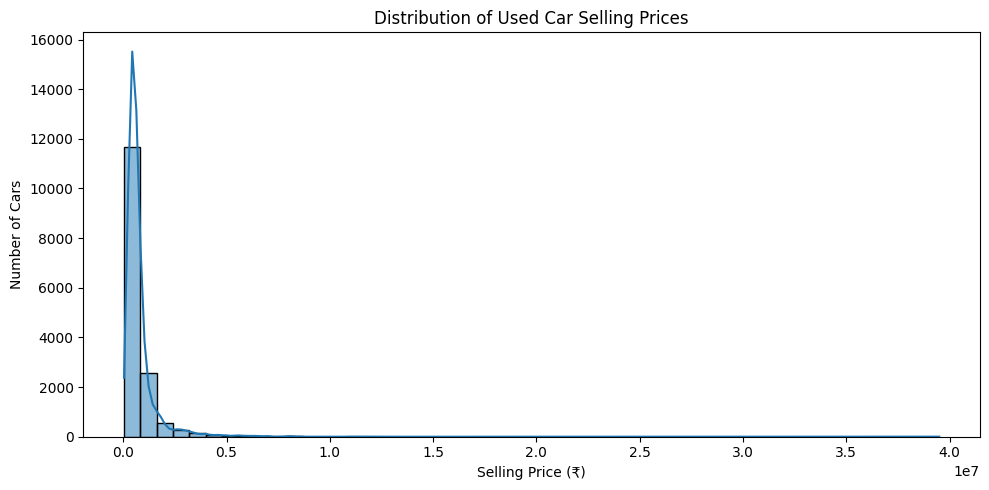

In [33]:
# Selling Price Distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="selling_price",
    bins=50,
    kde=True
)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

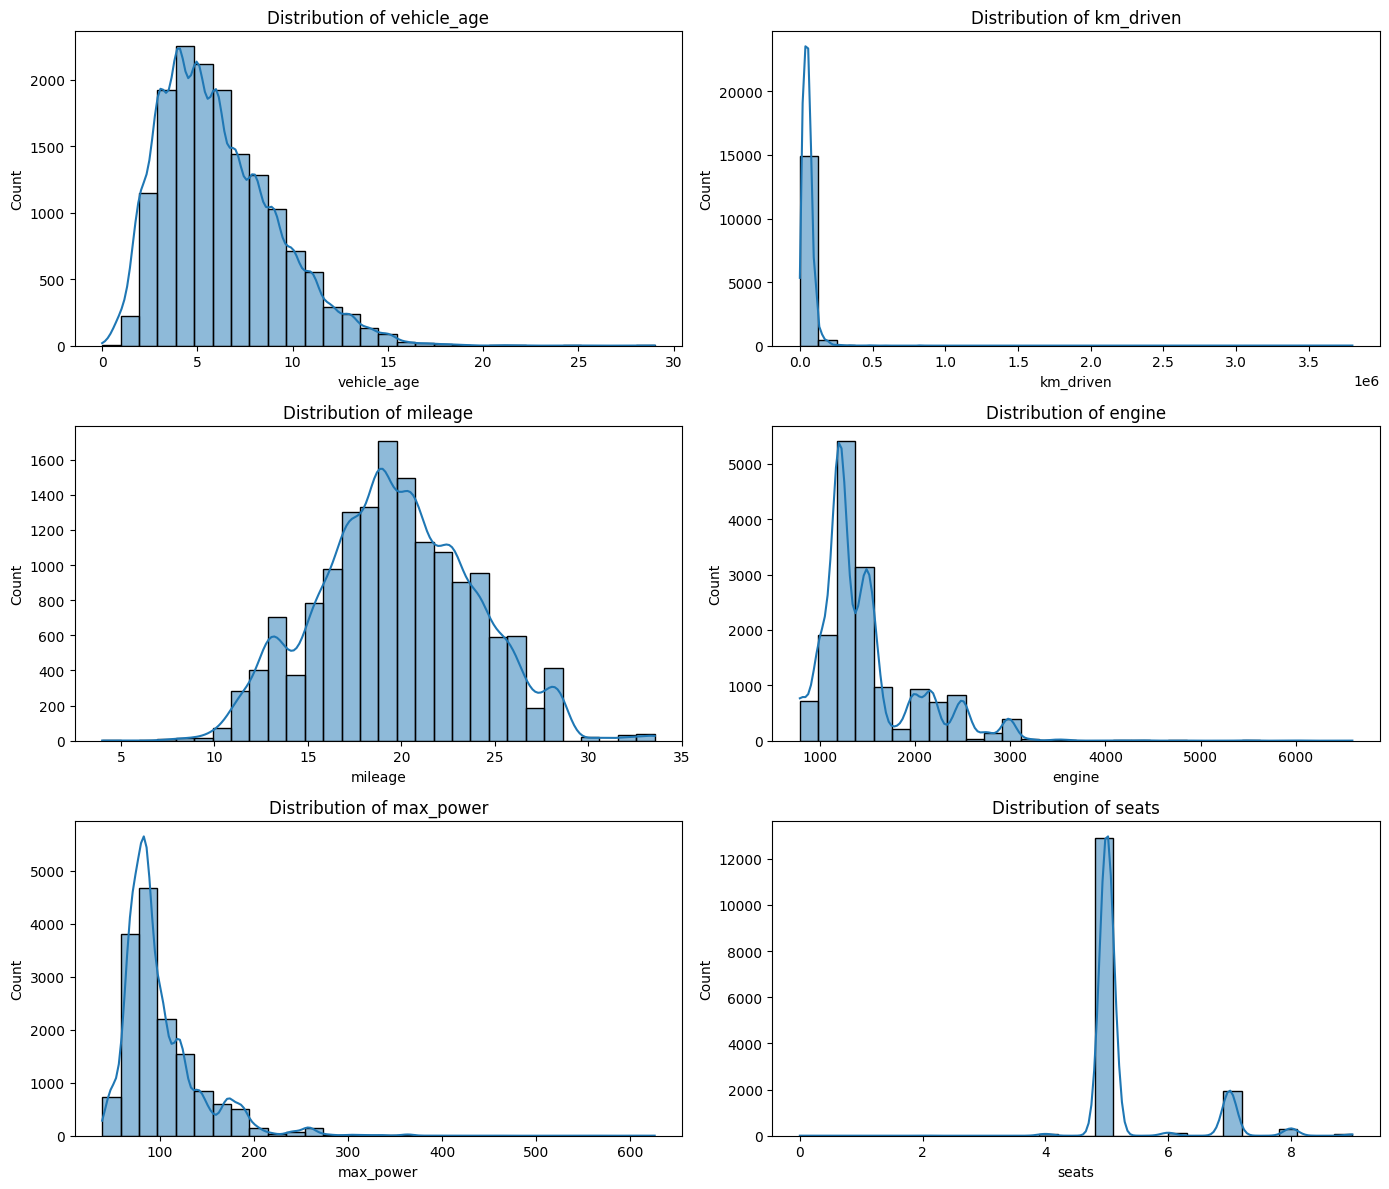

In [34]:
# Numerical Feature Distributions
features = [
    "vehicle_age",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for i, feature in enumerate(features):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f"Distribution of {feature}"
    )

plt.tight_layout()
plt.show()

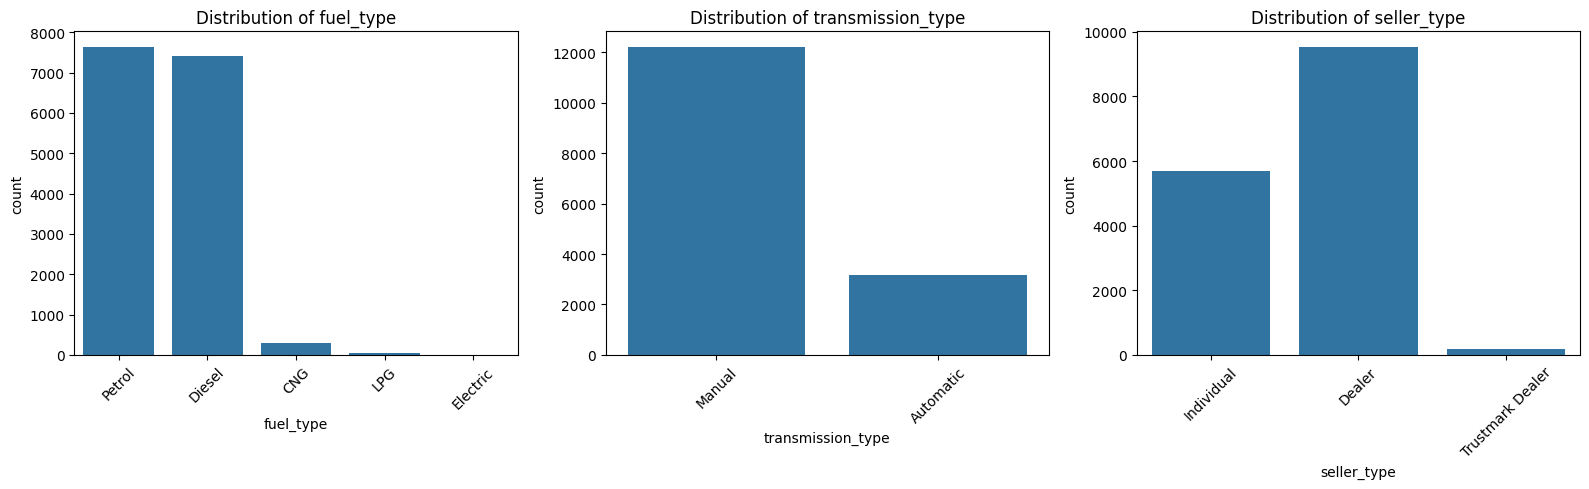

In [35]:
# Categorical Feature Distribution
features = [
    "fuel_type",
    "transmission_type",
    "seller_type"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(features):
    sns.countplot(
        data=df,
        x=feature,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution of {feature}"
    )

    axes[i].tick_params(
        axis="x",
        rotation=45
    )

plt.tight_layout()
plt.show()

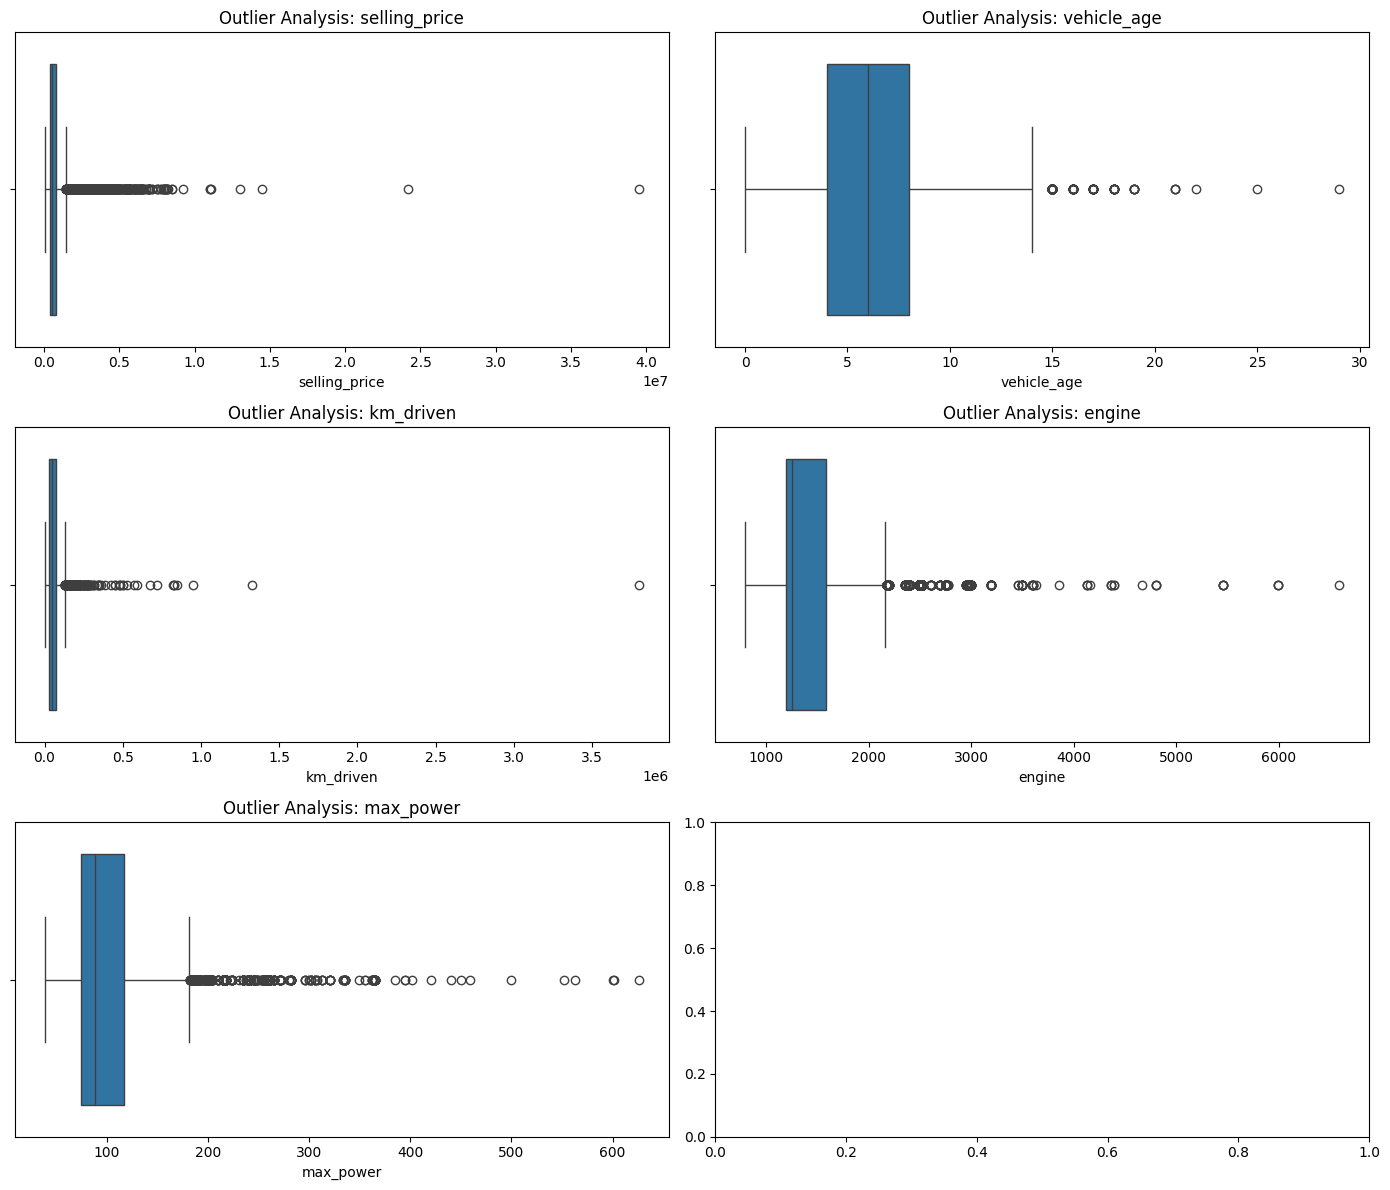

In [36]:
# Outlier Analysis
features = [
    "selling_price",
    "vehicle_age",
    "km_driven",
    "engine",
    "max_power"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for i, feature in enumerate(features):
    sns.boxplot(
        data=df,
        x=feature,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f"Outlier Analysis: {feature}"
    )

plt.tight_layout()
plt.show()

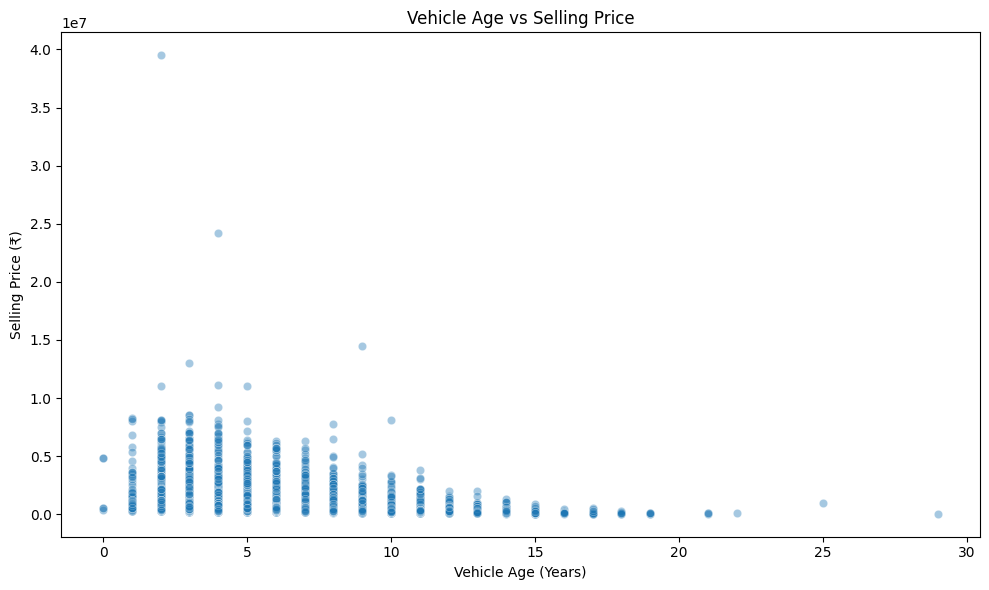

In [37]:
# Vehicle Age vs Selling Price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="vehicle_age",
    y="selling_price",
    alpha=0.4
)

plt.title("Vehicle Age vs Selling Price")
plt.xlabel("Vehicle Age (Years)")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

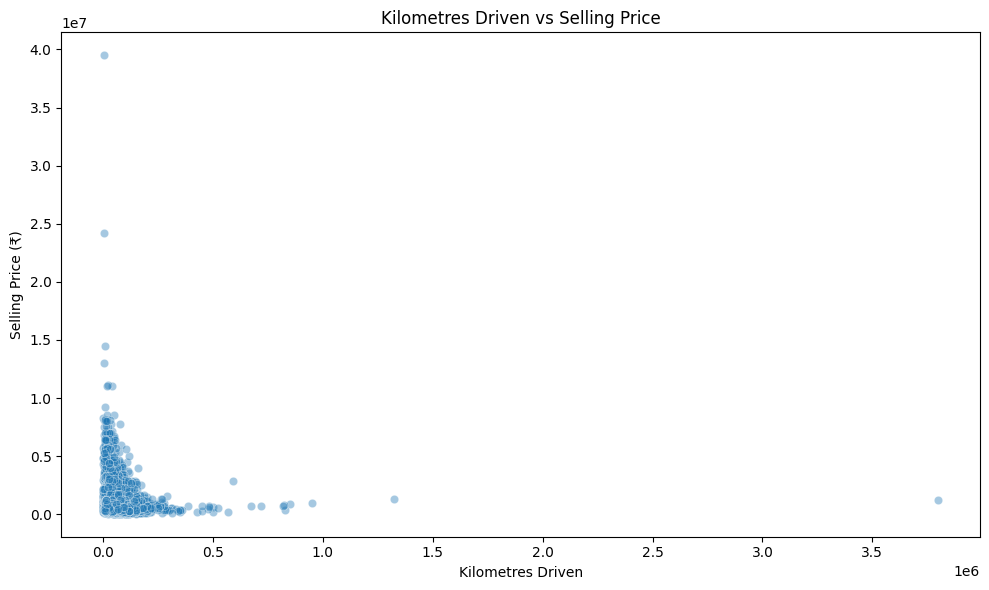

In [38]:
# Kilometres Driven vs Selling Price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="km_driven",
    y="selling_price",
    alpha=0.4
)

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.show()

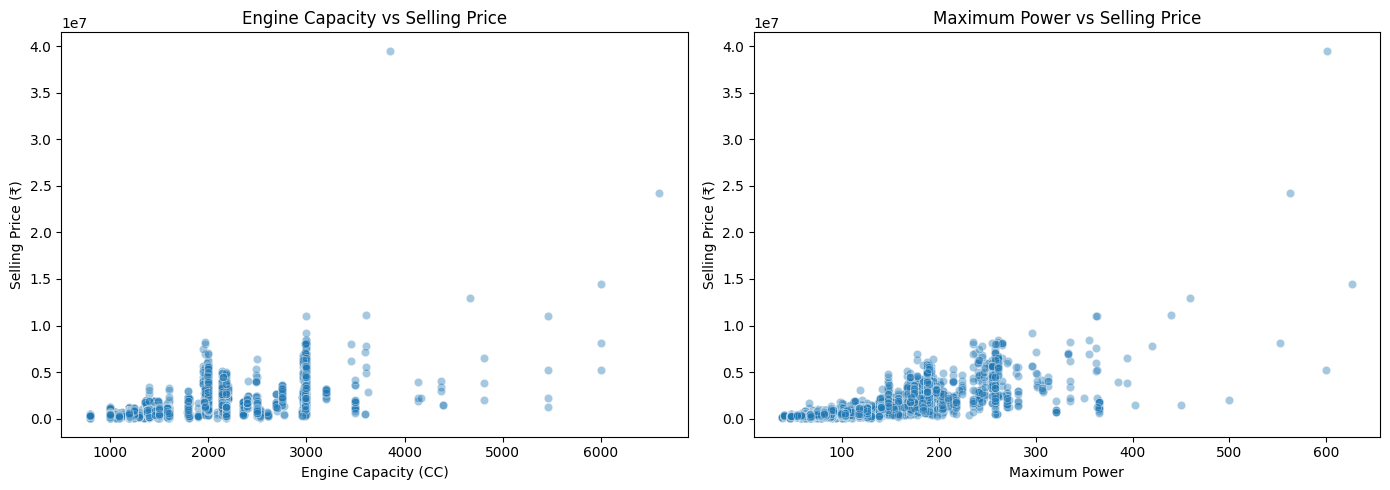

In [39]:
# Engine and Maximum Power vs Selling Price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df,
    x="engine",
    y="selling_price",
    alpha=0.4,
    ax=axes[0]
)

axes[0].set_title("Engine Capacity vs Selling Price")
axes[0].set_xlabel("Engine Capacity (CC)")
axes[0].set_ylabel("Selling Price (₹)")

sns.scatterplot(
    data=df,
    x="max_power",
    y="selling_price",
    alpha=0.4,
    ax=axes[1]
)

axes[1].set_title("Maximum Power vs Selling Price")
axes[1].set_xlabel("Maximum Power")
axes[1].set_ylabel("Selling Price (₹)")

plt.tight_layout()
plt.show()

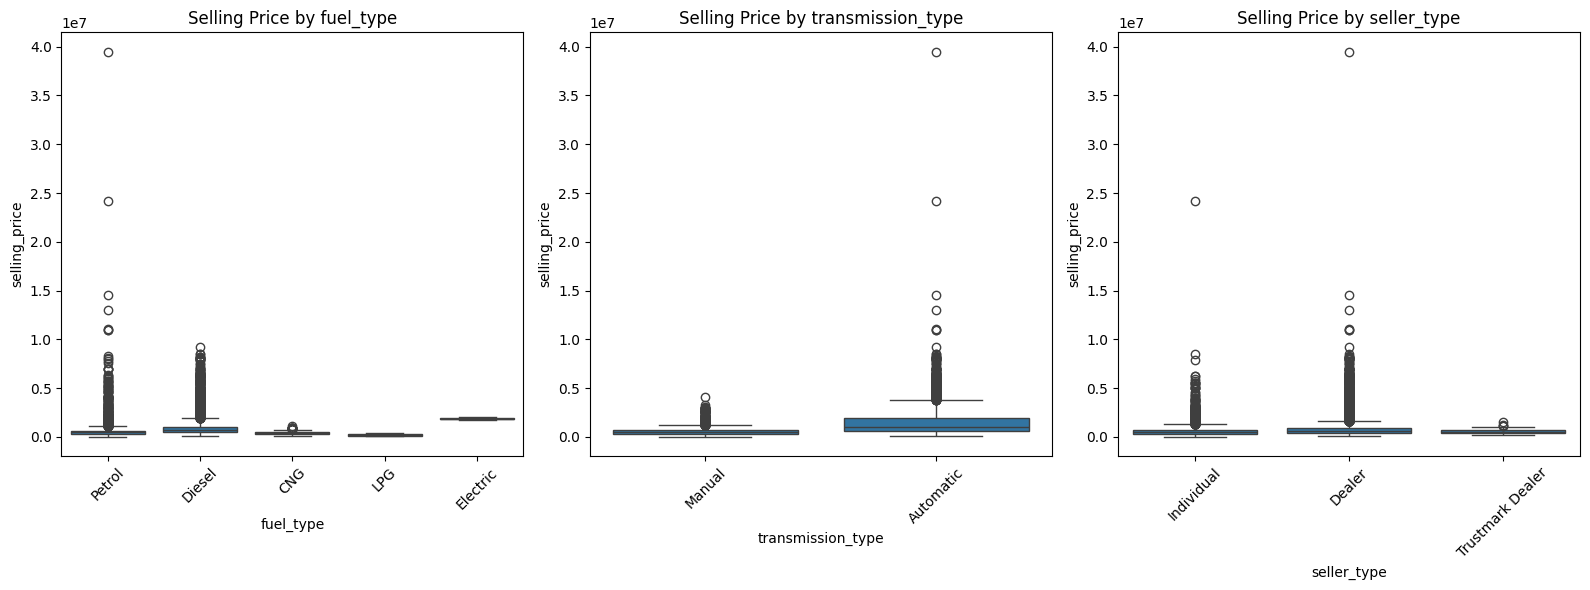

In [40]:
# Selling Price by Categorical Features
features = [
    "fuel_type",
    "transmission_type",
    "seller_type"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for i, feature in enumerate(features):
    sns.boxplot(
        data=df,
        x=feature,
        y="selling_price",
        ax=axes[i]
    )

    axes[i].set_title(
        f"Selling Price by {feature}"
    )

    axes[i].tick_params(
        axis="x",
        rotation=45
    )

plt.tight_layout()
plt.show()

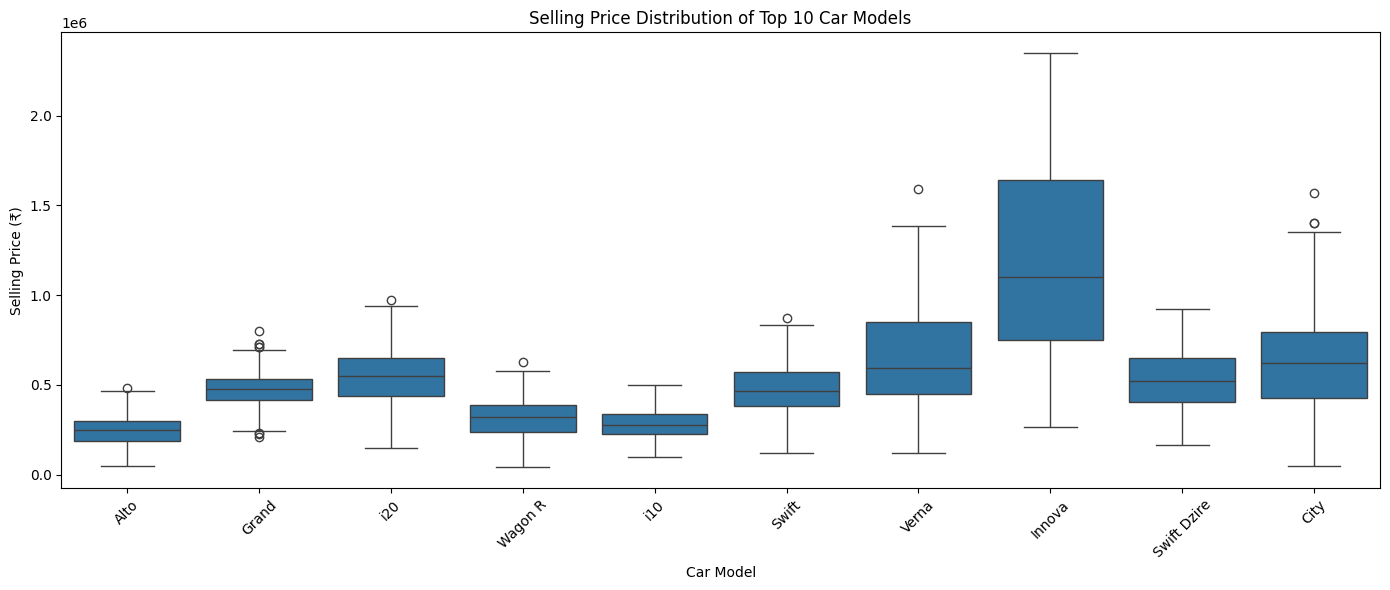

In [41]:
# Selling Price by Top 10 Car Models
top_models = df["model"].value_counts().head(10).index

top_model_data = df[df["model"].isin(top_models)]

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=top_model_data,
    x="model",
    y="selling_price"
)

plt.title("Selling Price Distribution of Top 10 Car Models")
plt.xlabel("Car Model")
plt.ylabel("Selling Price (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

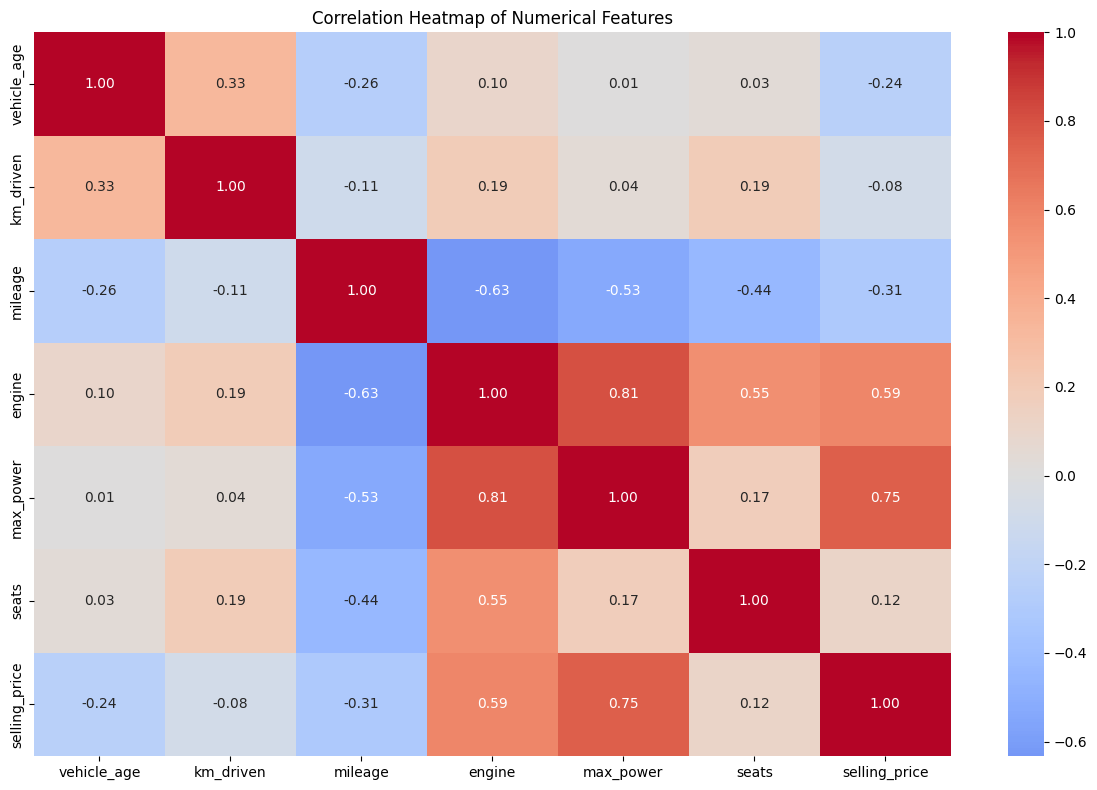

In [42]:
# Correlation Heatmap
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

## Feature Encoding and Scaling
**One Hot Encoding for Columns which had lesser unique values and not ordinal**
* One hot encoding is a process by which categorical variables are converted into a form that could be provided to ML algorithms to do a better job in prediction.

In [13]:
len(df['model'].unique())

120

In [14]:
df['model'].value_counts()

,count
model,
i20,906
Swift Dzire,890
Swift,781
Alto,778
City,757
...,...
Altroz,1
C,1
Ghost,1


In [15]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
X['model']=le.fit_transform(X['model'])

In [16]:
X.head()

,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats
0,7,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5
1,54,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5
2,118,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5
3,7,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5
4,38,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5


In [17]:
len(df['seller_type'].unique()),len(df['fuel_type'].unique()),len(df['transmission_type'].unique())

(3, 5, 2)

In [18]:
# Create Column Transformer with 3 types of transformers
num_features = X.select_dtypes(exclude="object").columns
onehot_columns = ['seller_type','fuel_type','transmission_type']

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_transformer = StandardScaler()
oh_transformer = OneHotEncoder(drop='first')

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", oh_transformer, onehot_columns),
        ("StandardScaler", numeric_transformer, num_features)

    ],remainder='passthrough'

)

In [19]:
X=preprocessor.fit_transform(X)

In [20]:
pd.DataFrame(X)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,-1.519714,0.983562,1.247335,-0.000276,-1.324259,-1.263352,-0.403022
1,1.0,0.0,0.0,0.0,0.0,1.0,1.0,-0.225693,-0.343933,-0.690016,-0.192071,-0.554718,-0.432571,-0.403022
2,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.536377,1.647309,0.084924,-0.647583,-0.554718,-0.479113,-0.403022
3,1.0,0.0,0.0,0.0,0.0,1.0,1.0,-1.519714,0.983562,-0.360667,0.292211,-0.936610,-0.779312,-0.403022
4,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-0.666211,-0.012060,-0.496281,0.735736,0.022918,-0.046502,-0.403022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.508844,0.983562,-0.869744,0.026096,-0.767733,-0.757204,-0.403022
15407,0.0,0.0,0.0,0.0,0.0,1.0,1.0,-0.556082,-1.339555,-0.728763,-0.527711,-0.216964,-0.220803,2.073444
15408,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.407551,-0.012060,0.220539,0.344954,0.022918,0.068225,-0.403022
15409,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.426247,-0.343933,72.541850,-0.887326,1.329794,0.917158,2.073444


In [21]:
# separate dataset into train and test
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape, X_test.shape

((12328, 14), (3083, 14))

In [22]:
X_train

array([[ 0.        ,  0.        ,  1.        , ...,  1.75390551,
         2.66249771, -0.40302241],
       [ 1.        ,  0.        ,  0.        , ..., -0.55087963,
        -0.38602844, -0.40302241],
       [ 0.        ,  0.        ,  1.        , ...,  0.89033072,
         3.27453006, -0.40302241],
       ...,
       [ 1.        ,  0.        ,  0.        , ..., -0.9366097 ,
        -0.78070786, -0.40302241],
       [ 0.        ,  0.        ,  0.        , ..., -0.55471774,
        -0.43582879, -0.40302241],
       [ 1.        ,  0.        ,  0.        , ..., -0.04616815,
         0.06194201, -0.40302241]], shape=(12328, 14))

## Model Training And Model Selection

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [24]:
##Create a Function to Evaluate Model
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [25]:
## Beginning Model Training
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),

}

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Evaluate Train and Test dataset
    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)


    print(list(models.keys())[i])

    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')

    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))

    print('='*35)
    print('\n')

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 553855.6665
- Mean Absolute Error: 268101.6071
- R2 Score: 0.6218
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 502543.5930
- Mean Absolute Error: 279618.5794
- R2 Score: 0.6645


Lasso
Model performance for Training set
- Root Mean Squared Error: 553855.6710
- Mean Absolute Error: 268099.2226
- R2 Score: 0.6218
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 502542.6696
- Mean Absolute Error: 279614.7461
- R2 Score: 0.6645


Ridge
Model performance for Training set
- Root Mean Squared Error: 553856.3160
- Mean Absolute Error: 268059.8015
- R2 Score: 0.6218
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 502533.8230
- Mean Absolute Error: 279557.2169
- R2 Score: 0.6645


K-Neighbors Regressor
Model performance for Training set
- Root Mean Squared Error: 325886.0010
- Mean 

In [26]:
#Initialize few parameter for Hyperparamter tuning
knn_params = {"n_neighbors": [2, 3, 10, 20, 40, 50]}
rf_params = {"max_depth": [5, 8, 15, None, 10],
             "max_features": [5, 7, "auto", 8],
             "min_samples_split": [2, 8, 15, 20],
             "n_estimators": [100, 200, 500, 1000]}


In [27]:
# Models list for Hyperparameter tuning
randomcv_models = [('KNN', KNeighborsRegressor(), knn_params),
                   ("RF", RandomForestRegressor(), rf_params)

                   ]

In [29]:
##Hyperparameter Tuning
from sklearn.model_selection import RandomizedSearchCV

model_param = {}
for name, model, params in randomcv_models:
    random = RandomizedSearchCV(estimator=model,
                                   param_distributions=params,
                                   n_iter=100,
                                   cv=3,
                                   verbose=2,
                                   n_jobs=-1)
    random.fit(X_train, y_train)
    model_param[name] = random.best_params_

for model_name in model_param:
    print(f"---------------- Best Params for {model_name} -------------------")
    print(model_param[model_name])

Fitting 3 folds for each of 6 candidates, totalling 18 fits


KeyboardInterrupt: 

In [ ]:
## Retraining the models with best parameters
models = {
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, min_samples_split=2, max_features=None, max_depth=None,
                                                     n_jobs=-1),
     "K-Neighbors Regressor": KNeighborsRegressor(n_neighbors=10, n_jobs=-1)

}
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i])

    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')

    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))

    print('='*35)
    print('\n')


## 4) Results & Conclusion

After benchmarking six regressors and tuning the top performers, the
**Random Forest Regressor** delivered the best generalisation on unseen data.

| Model | Test R² | Test RMSE (₹) |
|---|---|---|
| Linear / Lasso / Ridge | 0.66 | ~502,500 |
| Decision Tree | 0.87 | ~309,800 |
| K-Neighbors | 0.91 | ~253,100 |
| **Random Forest (tuned)** | **0.93** | **~228,400** |

### Key takeaways
* **Random Forest wins** — it explains ~93% of the variance in resale price and
  has the lowest test error, while staying far more robust than a single deep
  Decision Tree (which clearly overfit: 0.9995 train R² vs 0.87 test).
* Linear models underfit this problem — the price relationship is non-linear, so
  tree ensembles are a much better fit.
* `max_power`, `vehicle_age`, `engine` and `km_driven` are the strongest price
  drivers in the data.

### Next steps
* Add feature-importance and SHAP analysis for explainability.
* Persist the trained pipeline (`joblib`) and wrap it in a small API / Streamlit app.
* Engineer richer features (brand premium, mileage-per-year, segment buckets).

---
